# Ejercicio 4
## 4.a - Distancia de Enzo a la línea del arco

In [13]:
from matplotlib import pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import alc
import ejercicio3
import ejercicio4

filepath_base = '../template-alumnos/futbol'
img = mpimg.imread(f'{filepath_base}/test-gol-enzo.png')

### Puntos de referencia
Coordenadas en la cancha (m) y en la foto (px). Están definidos en `ejercicio4.py`.

In [14]:
objPts = ejercicio4.objPts
imgPts = ejercicio4.imgPts
print(objPts)
print(imgPts)

[[ 0.   30.34]
 [ 0.   37.66]
 [ 5.5  24.84]
 [ 5.5  43.16]
 [11.   34.  ]
 [16.5  26.69]
 [16.5  41.31]]
[[388.  176. ]
 [652.  184.5]
 [157.  231. ]
 [867.  250. ]
 [511.  317. ]
 [146.  406. ]
 [851.  422. ]]


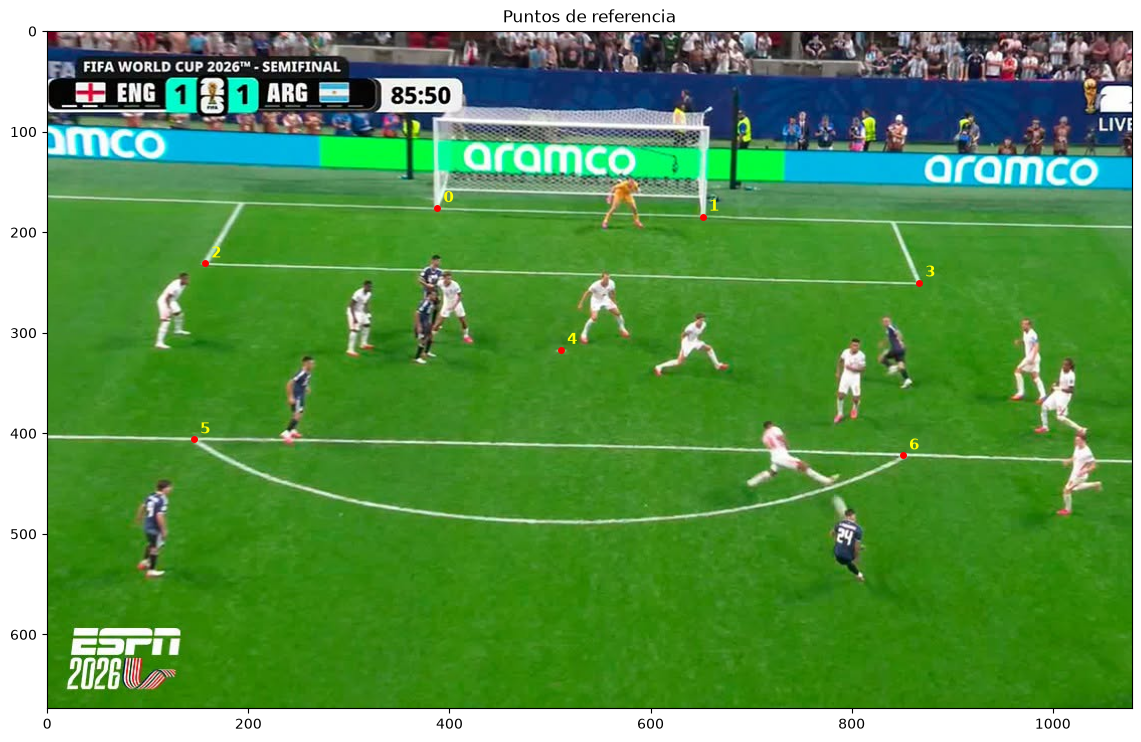

In [15]:
plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(imgPts[:, 0], imgPts[:, 1], 'ro', markersize=4)
for i in range(imgPts.shape[0]):
    plt.text(imgPts[i, 0] + 6, imgPts[i, 1] - 6, str(i), color='yellow', fontsize=11, weight='bold')
plt.title('Puntos de referencia')
plt.show()

### Homografía H (cancha -> imagen) y su inversa

In [16]:
H = ejercicio3.resolverDLT2D(imgPts, objPts)
H_inv = alc.inversa(H)
print(H / H[2, 2])

[[-9.53430568e+00  3.75647501e+01 -7.34465116e+02]
 [ 7.85950354e+00  1.32071535e+00  1.41846383e+02]
 [-1.67225458e-02  1.23844552e-03  1.00000000e+00]]


### Validación
Proyectamos el área chica. Sus esquinas sobre la línea de meta, (0, 24.84) y (0, 43.16), no se usaron para estimar H.

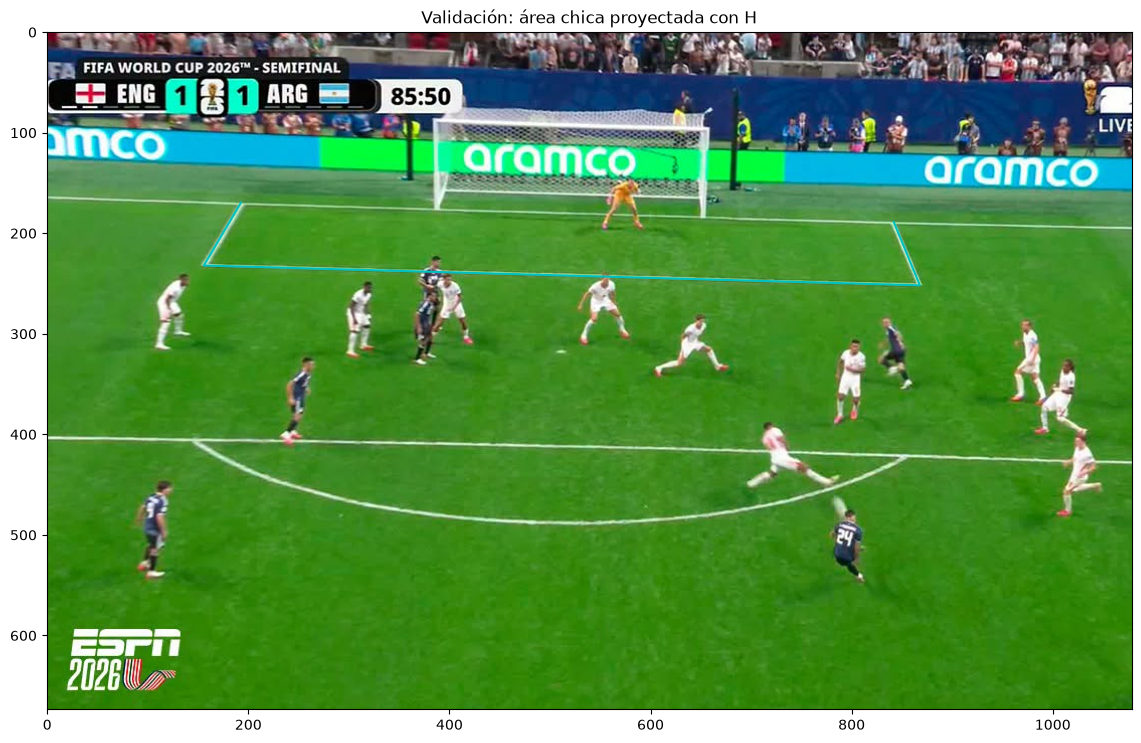

In [17]:
area_chica = ejercicio4.aplicarHomografia(H, np.array([[0.0, 24.84], [5.5, 24.84], [5.5, 43.16], [0.0, 43.16]]))

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(area_chica[:, 0], area_chica[:, 1], 'c-', linewidth=1.5)
plt.title('Validación: área chica proyectada con H')
plt.show()

### Posición de Enzo y distancia a la línea del arco

In [18]:
pie_enzo_img = ejercicio4.pie_enzo_img
U_enzo, V_enzo = ejercicio4.aplicarHomografia(H_inv, pie_enzo_img)[0]
distancia = np.abs(U_enzo)
print(f'Enzo en la cancha: U = {U_enzo:.2f} m, V = {V_enzo:.2f} m')
print(f'Distancia a la línea del arco: {distancia:.2f} m')

Enzo en la cancha: U = 22.24 m, V = 39.80 m
Distancia a la línea del arco: 22.24 m


In [19]:
linea_arco = np.array([[0, 31]])
u_arco, v_arco = ejercicio4.aplicarHomografia(H, linea_arco)[0]

print(f'Punto de referencia en imagen - Linea del Arco:')
print(f'U = {linea_arco[0][0]:.2f} m, V = {linea_arco[0][1]:.2f} m')
print(f'u = {u_arco:.2f}, v = {v_arco:.2f}')

Punto de referencia en imagen - Linea del Arco:
U = 0.00 m, V = 31.00 m
u = 414.14, v = 176.03


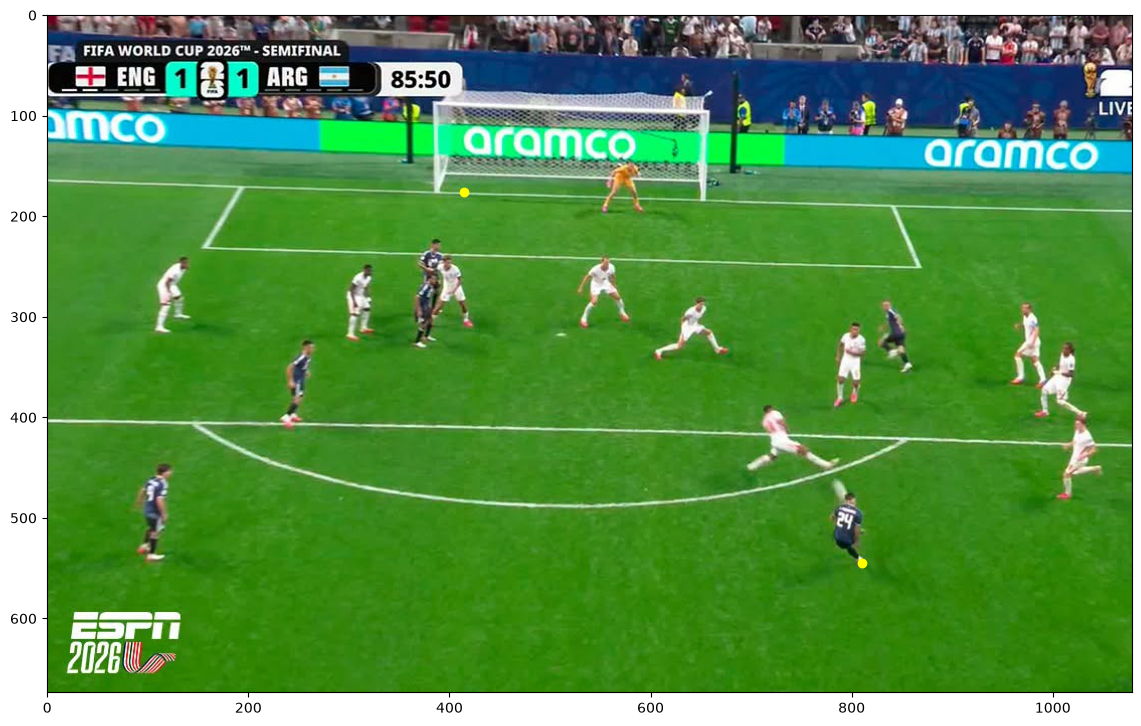

In [28]:
plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(pie_enzo_img[0][0], pie_enzo_img[0][1], 'o', color='yellow', markersize=6)
plt.plot(u_arco, v_arco, 'o', color='yellow', markersize=6)
plt.show()

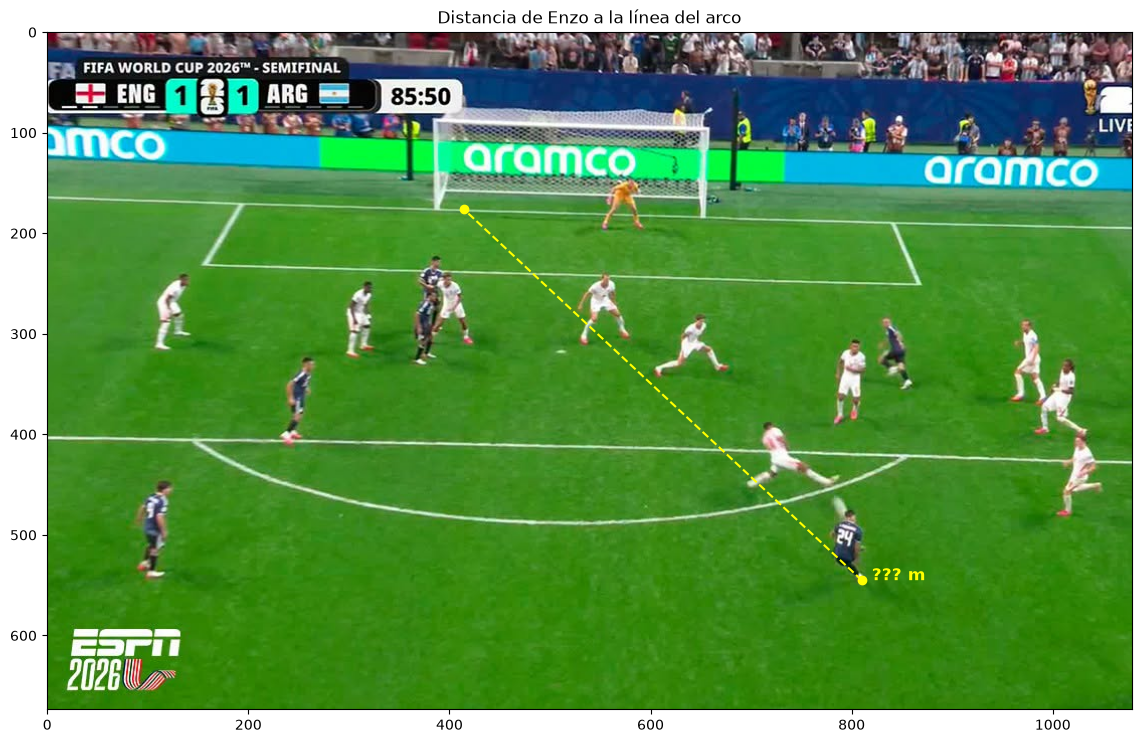

In [27]:
linea_enzo_arco = np.array([[pie_enzo_img[0, 0], u_arco], [pie_enzo_img[0,1], v_arco]])

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(pie_enzo_img[0, 0], pie_enzo_img[0, 1], 'o', color='yellow', markersize=6)
plt.plot(u_arco, v_arco, 'o', color='yellow', markersize=6)
plt.plot(linea_enzo_arco[0], linea_enzo_arco[1], '--', color='yellow', linewidth=1.5)
plt.text(pie_enzo_img[0, 0] + 10, pie_enzo_img[0, 1], f'{"???"} m', color='yellow', fontsize=12, weight='bold')
plt.title('Distancia de Enzo a la línea del arco')
plt.show()

## 4.b - Círculos de 1 m de radio alrededor de los jugadores argentinos
Usamos la misma $\mathbf{H}$ del 4.a. Para cada jugador: llevamos su pie a la cancha con $\mathbf{H}^{-1}$, armamos ahí el círculo de 1 m de radio con `circuloEnCancha` (sin seno ni coseno, despejando $V = V_0 \pm \sqrt{r^2 - (U - U_0)^2}$) y proyectamos sus puntos a la foto con $\mathbf{H}$.

Los pies se marcaron a mano. El jugador de atrás del grupo del medio tiene los pies tapados por su compañero, así que su posición se estimó por la bota que se ve y es la menos precisa.

In [22]:
pies_argentinos_img = ejercicio4.pies_argentinos_img
pies_cancha = ejercicio4.aplicarHomografia(H_inv, pies_argentinos_img)
for i in range(pies_cancha.shape[0]):
    print(f'Jugador {i}: U = {pies_cancha[i, 0]:.2f} m, V = {pies_cancha[i, 1]:.2f} m')

Jugador 0: U = 22.53 m, V = 27.14 m
Jugador 1: U = 16.33 m, V = 28.65 m
Jugador 2: U = 9.79 m, V = 31.07 m
Jugador 3: U = 11.83 m, V = 30.94 m
Jugador 4: U = 12.59 m, V = 41.85 m
Jugador 5: U = 22.24 m, V = 39.80 m


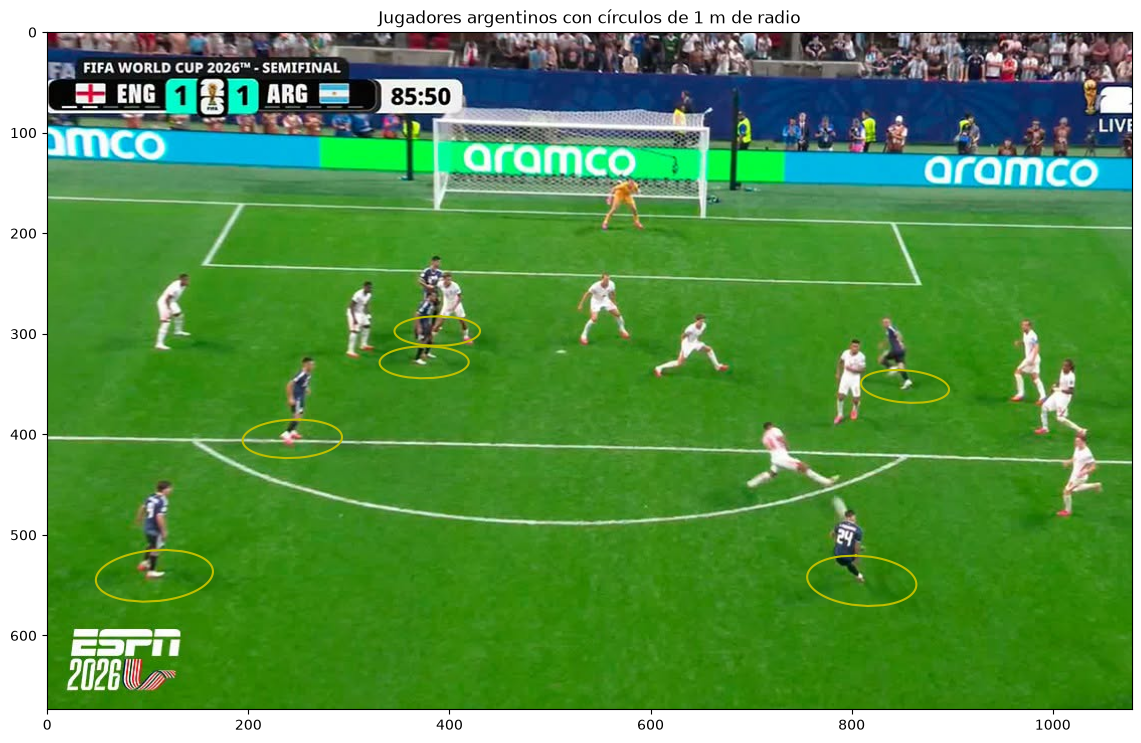

In [23]:
plt.figure(figsize=(14, 9))
plt.imshow(img)
for i in range(pies_cancha.shape[0]):
    circulo_img = ejercicio4.aplicarHomografia(H, ejercicio4.circuloEnCancha(pies_cancha[i], 1.0, 50))
    plt.plot(circulo_img[:, 0], circulo_img[:, 1], 'y-', linewidth=1.5)
plt.title('Jugadores argentinos con círculos de 1 m de radio')
plt.show()

El jugador que está sobre la línea del área da $U \approx 16.33$ m, muy cerca del valor real $16.5$ m, lo que confirma que $\mathbf{H}$ funciona bien también fuera de los puntos de referencia.